# Eksperimen Detektor ROI Otsu
Protokol (Panduan Bagian 3 dan 9): tuning **hanya** pada `val`; `test` dievaluasi sekali setelah B2 dibekukan.
B1 = Otsu + Gray World awal (preset di modul). B2 dibekukan dalam dua varian:
- **B2-F1**: F1 tertinggi pada val.
- **B2-crop**: F1 tertinggi dengan syarat `crop_success_rate >= MIN_CROP_SUCCESS` (keutuhan potongan penting bagi Tahap 4).

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import otsu_roi as roi

B2_F1_PATH = Path("b2_params.json")
B2_CROP_PATH = Path("b2_crop_params.json")
MIN_CROP_SUCCESS = 0.80   # tetapkan dari val SEBELUM test dibuka; jangan diubah setelah melihat test

val = roi.load_samples("val")
print(len(val), "citra val")

46 citra val


## 1. B1 pada val

In [2]:
b1_val = roi.evaluate(roi.PRESET_B1, val)
pd.Series(b1_val)

n_images             46.000000
precision             0.034146
recall                0.145833
f1                    0.055336
map50                 0.014532
mean_iou              0.701294
crop_success_rate     0.770833
count_accuracy        0.173913
no_detection_rate     0.000000
mean_roi_frac         0.755452
dtype: float64

## 2. Grid search pada val
Periksa `n_combinations` sebelum menjalankan. `channel` diabaikan pada gray, jadi ada kombinasi duplikat.

In [3]:
GRID = {
    "norm_mode":     ["none", "gray_world"],
    "color_space":   ["gray", "lab", "hsv"],
    "channel":       [0, 1, 2],
    "blur_ksize":    [3, 5, 7],
    "polarity":      ["auto", "dark", "bright"],
    "open_ksize":    [0, 3],
    "close_ksize":   [3, 7, 15],
    "min_area_frac": [0.002, 0.01],
}
n_combinations = 1
for values in GRID.values():
    n_combinations *= len(values)
print("n_combinations:", n_combinations)

n_combinations: 1944


In [4]:
results = roi.grid_search(val, GRID)
table = pd.DataFrame([{**vars(p), **m} for p, m in results])
table.to_csv("tuning_results.csv", index=False)
table.head(10)

,norm_mode,color_space,channel,blur_ksize,polarity,open_ksize,close_ksize,min_area_frac,max_area_frac,padding_frac,n_images,precision,recall,f1,map50,mean_iou,crop_success_rate,count_accuracy,no_detection_rate,mean_roi_frac
0,none,hsv,1,5,bright,3,3,0.01,0.95,0.0,46,0.193548,0.375000,0.255319,0.117408,0.644328,0.500000,0.434783,0.021739,0.458835
1,none,hsv,1,5,bright,0,3,0.01,0.95,0.0,46,0.193548,0.375000,0.255319,0.116736,0.626127,0.541667,0.413043,0.021739,0.480502
2,gray_world,hsv,1,5,auto,0,3,0.01,0.95,0.0,46,0.180952,0.395833,0.248366,0.131469,0.706396,0.270833,0.282609,0.021739,0.323563
3,gray_world,hsv,1,5,bright,0,3,0.01,0.95,0.0,46,0.180952,0.395833,0.248366,0.131469,0.706396,0.270833,0.282609,0.021739,0.323563
4,none,hsv,1,5,auto,0,3,0.01,0.95,0.0,46,0.183673,0.375000,0.246575,0.117196,0.628101,0.520833,0.391304,0.021739,0.468114
5,none,hsv,1,5,auto,3,3,0.01,0.95,0.0,46,0.181818,0.375000,0.244898,0.118601,0.646301,0.479167,0.391304,0.021739,0.445491
6,gray_world,hsv,1,3,auto,0,3,0.01,0.95,0.0,46,0.171429,0.375000,0.235294,0.111116,0.703941,0.312500,0.282609,0.021739,0.331807
7,gray_world,hsv,1,3,bright,0,3,0.01,0.95,0.0,46,0.171429,0.375000,0.235294,0.111116,0.703941,0.312500,0.282609,0.021739,0.331807
8,none,lab,2,7,bright,3,7,0.01,0.95,0.0,46,0.196970,0.270833,0.228070,0.074911,0.744070,0.750000,0.695652,0.021739,0.644576
9,none,lab,2,3,bright,3,7,0.01,0.95,0.0,46,0.196970,0.270833,0.228070,0.074911,0.734299,0.750000,0.717391,0.021739,0.649242


## 3. Bekukan B2-F1 dan B2-crop

In [5]:
b2_f1, b2_f1_val = roi.select_best(results)
b2_crop, b2_crop_val = roi.select_best(results, MIN_CROP_SUCCESS)
roi.freeze_params(B2_F1_PATH, b2_f1, b2_f1_val)
roi.freeze_params(B2_CROP_PATH, b2_crop, b2_crop_val)
pd.DataFrame({"B1": b1_val, "B2-F1": b2_f1_val, "B2-crop": b2_crop_val})

,B1,B2-F1,B2-crop
n_images,46.000000,46.000000,46.000000
precision,0.034146,0.193548,0.172414
recall,0.145833,0.375000,0.208333
f1,0.055336,0.255319,0.188679
map50,0.014532,0.117408,0.048450
mean_iou,0.701294,0.644328,0.729145
crop_success_rate,0.770833,0.500000,0.833333
count_accuracy,0.173913,0.434783,0.739130
no_detection_rate,0.000000,0.021739,0.021739
mean_roi_frac,0.755452,0.458835,0.746663


## 4. Pemeriksaan data test
Citra tanpa GT dihitung sebagai negatif. Jika banyak yang sebenarnya belum dianotasi, precision dan count accuracy keliru.

In [6]:
test = roi.load_samples("test")
n_empty = sum(not s.gt_boxes for s in test)
print(f"{len(test)} citra test, {n_empty} tanpa GT, {sum(len(s.gt_boxes) for s in test)} objek GT")
print(f"{len(val)} citra val,  {sum(not s.gt_boxes for s in val)} tanpa GT, {sum(len(s.gt_boxes) for s in val)} objek GT")

46 citra test, 0 tanpa GT, 49 objek GT
46 citra val,  0 tanpa GT, 48 objek GT


## 5. Evaluasi akhir pada test (sekali) + selisih val vs test

In [7]:
b2_f1 = roi.OtsuParams.from_json(B2_F1_PATH)
b2_crop = roi.OtsuParams.from_json(B2_CROP_PATH)
configs = {"B1": roi.PRESET_B1, "B2-F1": b2_f1, "B2-crop": b2_crop}

test_table = pd.DataFrame({name: roi.evaluate(p, test) for name, p in configs.items()})
val_table = pd.DataFrame({name: roi.evaluate(p, val) for name, p in configs.items()})
display(test_table)
print("test - val (selisih besar = indikasi overfit ke val):")
display(test_table - val_table)

,B1,B2-F1,B2-crop
n_images,46.000000,46.000000,46.000000
precision,0.053571,0.182796,0.157895
recall,0.183673,0.346939,0.183673
f1,0.082949,0.239437,0.169811
map50,0.026882,0.099674,0.030612
mean_iou,0.745147,0.742809,0.868329
crop_success_rate,0.795918,0.428571,0.836735
count_accuracy,0.152174,0.413043,0.782609
no_detection_rate,0.000000,0.000000,0.021739
mean_roi_frac,0.748118,0.489169,0.758858


test - val (selisih besar = indikasi overfit ke val):


,B1,B2-F1,B2-crop
n_images,0.000000,0.000000,0.000000
precision,0.019425,-0.010753,-0.014519
recall,0.037840,-0.028061,-0.024660
f1,0.027613,-0.015883,-0.018868
map50,0.012350,-0.017734,-0.017837
mean_iou,0.043853,0.098481,0.139183
crop_success_rate,0.025085,-0.071429,0.003401
count_accuracy,-0.021739,-0.021739,0.043478
no_detection_rate,0.000000,-0.021739,0.000000
mean_roi_frac,-0.007334,0.030334,0.012195


## 6. Interval kepercayaan 95% (bootstrap per citra)
Selisih berpasangan terhadap B1: interval yang memuat 0 berarti selisihnya belum dapat dibedakan dari derau.

In [8]:
ci = pd.DataFrame({name: {m: f"{lo:.3f}-{hi:.3f}" for m, (lo, hi) in roi.bootstrap_ci(p, test).items()}
                   for name, p in configs.items()})
display(ci)

rows = {}
for name in ("B2-F1", "B2-crop"):
    diff = roi.bootstrap_paired_difference(roi.PRESET_B1, configs[name], test)
    rows[f"{name} - B1"] = {m: f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]" for m, (d, lo, hi) in diff.items()}
pd.DataFrame(rows)

,B1,B2-F1,B2-crop
precision,0.026-0.088,0.110-0.270,0.071-0.268
recall,0.082-0.304,0.207-0.500,0.085-0.300
f1,0.039-0.134,0.144-0.349,0.078-0.278
map50,0.007-0.079,0.039-0.223,0.007-0.085
mean_iou,0.668-0.817,0.667-0.814,0.800-0.917
crop_success_rate,0.680-0.898,0.283-0.583,0.736-0.925
count_accuracy,0.065-0.261,0.283-0.543,0.652-0.891
no_detection_rate,0.000-0.000,0.000-0.000,0.000-0.065
mean_roi_frac,0.688-0.800,0.406-0.569,0.671-0.841


,B2-F1 - B1,B2-crop - B1
precision,"+0.131 [+0.059, +0.203]","+0.106 [+0.019, +0.206]"
recall,"+0.161 [+0.020, +0.313]","-0.003 [-0.130, +0.128]"
f1,"+0.157 [+0.062, +0.247]","+0.087 [-0.008, +0.191]"
map50,"+0.084 [+0.012, +0.184]","+0.003 [-0.043, +0.054]"
mean_iou,"-0.004 [-0.087, +0.080]","+0.122 [+0.059, +0.196]"
crop_success_rate,"-0.368 [-0.560, -0.184]","+0.039 [-0.106, +0.188]"
count_accuracy,"+0.262 [+0.108, +0.413]","+0.632 [+0.500, +0.761]"
no_detection_rate,"+0.000 [+0.000, +0.000]","+0.022 [+0.000, +0.065]"
mean_roi_frac,"-0.259 [-0.341, -0.177]","+0.010 [-0.080, +0.095]"


## 7. Kasus terburuk (test)

,image_id,n_pred,n_gt,best_iou
0,KGL_0070,0,1,0.000000
1,KGL_0105,1,1,0.008036
2,KGL_0156,1,1,0.014180
3,KGL_0052,1,1,0.020232


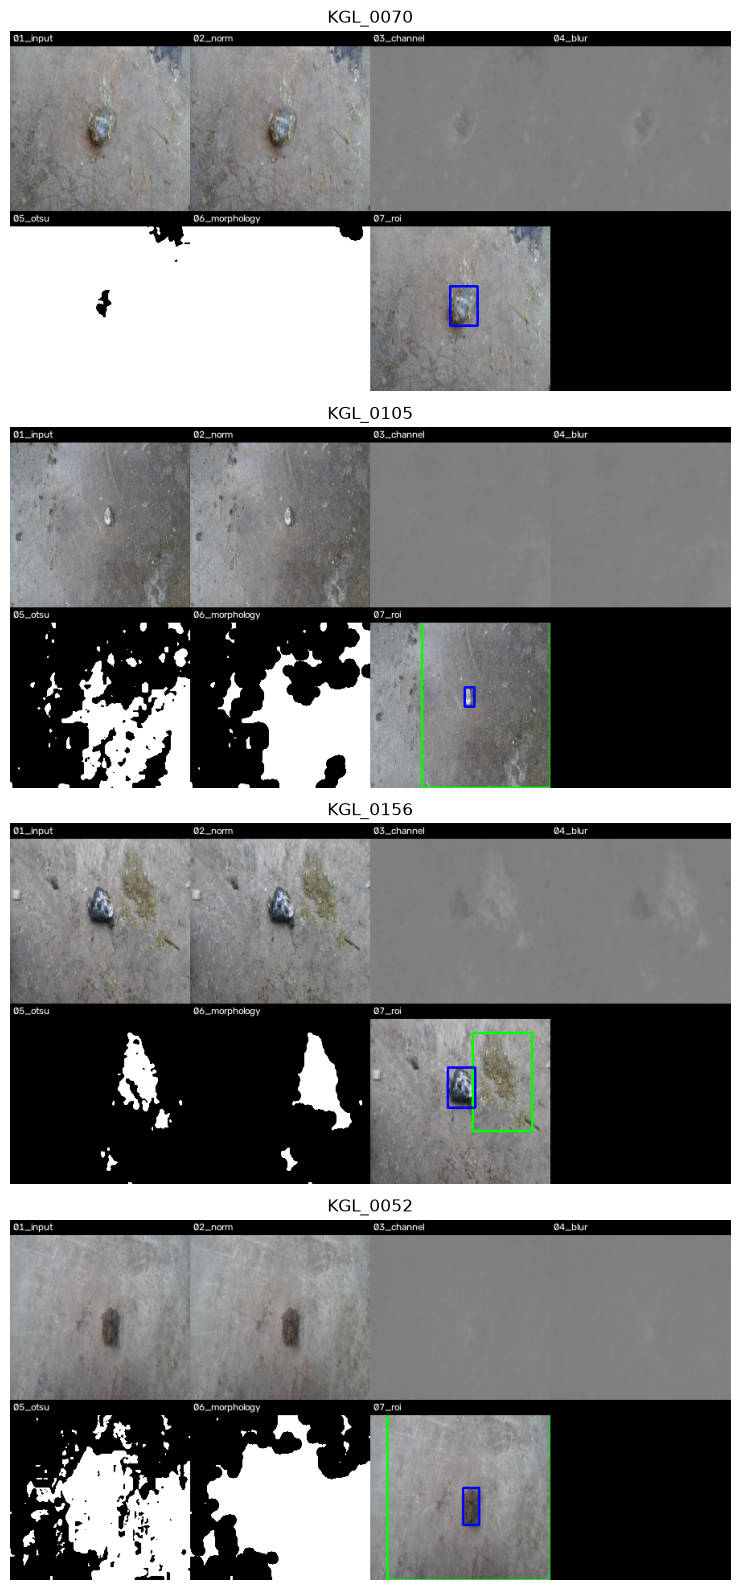

In [9]:
chosen = b2_crop
report = pd.DataFrame(roi.per_image_report(chosen, test))
worst = report.head(4)
display(worst)
by_id = {s.image_id: s for s in test}
fig, axes = plt.subplots(len(worst), 1, figsize=(16, 4 * len(worst)))
for ax, image_id in zip(axes, worst["image_id"]):
    ax.imshow(cv2.cvtColor(roi.make_montage(by_id[image_id], chosen), cv2.COLOR_BGR2RGB))
    ax.set_title(image_id); ax.axis("off")
plt.tight_layout()